# Weather data from ERA5, with xarray

**AI SCI 290A · Project starter: weather**

This notebook shows how to open, explore and plot weather data from **ERA5**, and introduces **xarray**, the Python library for labeled multi-dimensional data.

**ERA5** is a *reanalysis* produced by the European Centre for Medium-Range Weather Forecasts (ECMWF). A reanalysis combines a weather model with past observations to give a complete, consistent estimate of the weather everywhere on a regular grid, including places and times with no measurements. ERA5 covers the whole globe on a 0.25° grid (about 28 km), hourly, from 1940 to the present.

The files for this project are a small piece of it:

| | |
|---|---|
| Region | Continental US: latitude 24° to 50° N, longitude 125° to 66° W |
| Time | Every day of 2009 (daily means) |
| Variables | Temperature at 2 m, precipitation, sea-level pressure, and the two components of the wind at 10 m |
| Format | netCDF (`.nc`), split into six two-month folders |

What we'll do:

1. Set up and find the files
2. Learn what an xarray `DataArray` and `Dataset` are, on a tiny example
3. Open the ERA5 temperature data
4. Make maps
5. Make a time series for one city
6. Look at precipitation, and check its units
7. Combine all the variables, and compute wind speed, monthly averages and regional averages
8. Hand the data to pandas for machine learning

## 1. Setup

You need `xarray`, `netcdf4` and `dask`. All three are in the course `290A` environment.

Put the data folders in a folder called `data/` next to this notebook:

```
weather/
├─ weather_era5_xarray.ipynb
└─ data/
   ├─ 2009_JanFeb/
   ├─ 2009_MarchApril/
   ├─ ...
   └─ 2009_NovDec/
```

If your data is somewhere else, change `DATA_DIR` below.

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "coolwarm"

print("xarray", xr.__version__)

xarray 2025.6.1


In [3]:
print("Current directory:", os.getcwd())
print("Files and folders:", os.listdir("."))
print("Data folder exists:", os.path.exists("data"))

Current directory: /Users/jesse/290A/Project1
Files and folders: ['.DS_Store', 'weather_era5_xarray.ipynb', '.ipynb_checkpoints', 'data:']
Data folder exists: False


In [11]:
DATA_DIR = "data:/data"

all_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*.nc")))
print(f"Found {len(all_files)} files in {DATA_DIR}")
for f in all_files[:5]:
    print("  ", os.path.relpath(f, DATA_DIR))
print("   ...")

Found 60 files in data:/data
   2009_JanFeb/10m_u_component_of_wind_stream-oper_daily-mean.nc
   2009_JanFeb/10m_v_component_of_wind_0_daily-mean.nc
   2009_JanFeb/2m_temperature_0_daily-mean.nc
   2009_JanFeb/mean_sea_level_pressure_0_daily-mean.nc
   2009_JanFeb/total_precipitation_0_daily-mean.nc
   ...


Each folder holds two months, with one file per variable. You should see 30 files: 6 folders × 5 variables. If you see 0, check `DATA_DIR`.

## 2. The xarray data structure

Weather data is naturally **multi-dimensional**: a temperature for every day, at every latitude, at every longitude. A NumPy array can hold those numbers, but it only knows *positions*: `T[180, 32, 150]`. You have to remember yourself that axis 0 is time, that position 180 is 30 June, and that latitude 32 is 42° N.

**xarray** attaches those labels to the array. You can then write `T.sel(valid_time="2009-06-30", latitude=42)`, and xarray finds the right positions.

### `DataArray`: one variable

A `DataArray` is a NumPy array plus labels:

| Part | What it is | Our temperature data |
|---|---|---|
| `values` | the numbers, as a NumPy array | 365 × 105 × 237 temperatures |
| `dims` | a name for each axis | `("valid_time", "latitude", "longitude")` |
| `coords` | the label for each position along each axis | the 365 dates, 105 latitudes, 237 longitudes |
| `attrs` | metadata | `units: K`, `long_name: 2 metre temperature` |
| `name` | the variable's name | `t2m` |

### `Dataset`: several variables on the same grid

A `Dataset` is a collection of `DataArray`s that share coordinates, like a pandas `DataFrame` is a collection of columns that share an index. Our ERA5 files open as `Dataset`s; you take one variable out with `ds["t2m"]`.

### How it compares

| | NumPy | pandas | xarray |
|---|---|---|---|
| Dimensions | any | 1 or 2 | any |
| Labels | none | index and columns | a coordinate for every dimension |
| Select by label | no | `.loc` | `.sel` |
| Select by position | `a[0]` | `.iloc` | `.isel` |

## 3. A quick xarray primer

Before the real data, here is a tiny `DataArray` built by hand: temperatures on 3 days at 2 latitudes and 3 longitudes. Everything you learn here works the same way on the full dataset.

In [12]:
values = np.array([
    [[ 2,  4,  6], [12, 14, 16]],   # day 1: northern row, southern row
    [[ 3,  5,  7], [13, 15, 17]],   # day 2
    [[ 1,  3,  5], [11, 13, 15]],   # day 3
], dtype=float)

toy = xr.DataArray(
    values,
    dims=("time", "lat", "lon"),
    coords={
        "time": pd.date_range("2009-01-01", periods=3),
        "lat": [45.0, 35.0],
        "lon": [-120.0, -100.0, -80.0],
    },
    name="temperature",
    attrs={"units": "degC"},
)
toy

<xarray.DataArray 'temperature' (time: 3, lat: 2, lon: 3)> Size: 144B
array([[[ 2.,  4.,  6.],
        [12., 14., 16.]],

       [[ 3.,  5.,  7.],
        [13., 15., 17.]],

       [[ 1.,  3.,  5.],
        [11., 13., 15.]]])
Coordinates:
  * time     (time) datetime64[ns] 24B 2009-01-01 2009-01-02 2009-01-03
  * lat      (lat) float64 16B 45.0 35.0
  * lon      (lon) float64 24B -120.0 -100.0 -80.0
Attributes:
    units:    degC

In Jupyter, the last line of a cell shows the array as an interactive summary: click the icons on the right to see coordinates and attributes. Each part is also available directly:

In [13]:
print("dims:  ", toy.dims)
print("shape: ", toy.shape)
print("units: ", toy.attrs["units"])
print("latitudes:", toy["lat"].values)
print()
print(toy.values[0])    # the plain NumPy array, first day

dims:   ('time', 'lat', 'lon')
shape:  (3, 2, 3)
units:  degC
latitudes: [45. 35.]

[[ 2.  4.  6.]
 [12. 14. 16.]]


### Selecting data

| Method | Selects by | Example |
|---|---|---|
| `.isel()` | position (like NumPy) | `toy.isel(time=0)`: the first day |
| `.sel()` | coordinate label | `toy.sel(lat=35.0)`: the row at 35° N |
| `.sel(..., method="nearest")` | closest label | `toy.sel(lat=33.2, method="nearest")` |
| `.sel(x=slice(a, b))` | a range of labels | `toy.sel(lon=slice(-125, -90))` |

Selecting one value along a dimension removes that dimension.

In [14]:
print(toy.isel(time=0).dims)                       # first day: a lat × lon map
print(toy.sel(lat=35.0).dims)                      # one latitude: time × lon
print(toy.sel(lat=33.2, lon=-97, method="nearest").values)  # nearest grid point: 3 values over time
print(toy.sel(lon=slice(-125, -90))["lon"].values) # a range of longitudes

('lat', 'lon')
('time', 'lon')
[14. 15. 13.]
[-120. -100.]


### Calculations

Arithmetic works like NumPy, and the labels come along. Reductions such as `.mean()` take a **dimension name** instead of an axis number, which is much harder to get wrong.

In [15]:
print(toy.mean(dim="time").values)            # average over days: a lat × lon map
print()
print(toy.mean(dim=["lat", "lon"]).values)    # average over space: one number per day
print()
toy_F = toy * 9 / 5 + 32                      # convert to Fahrenheit: coordinates are kept
print(toy_F.sel(lat=45.0, lon=-80.0).values)

[[ 2.  4.  6.]
 [12. 14. 16.]]

[ 9. 10.  8.]

[42.8 44.6 41. ]


One thing to know: arithmetic drops the `attrs`, because xarray can't know whether the units still apply. After a conversion, set the new units yourself, as in `toy_F.attrs["units"] = "degF"`.

### Plotting

`.plot()` picks a sensible plot from the number of dimensions: a line for 1D, a colored map for 2D. It labels the axes from the coordinates.

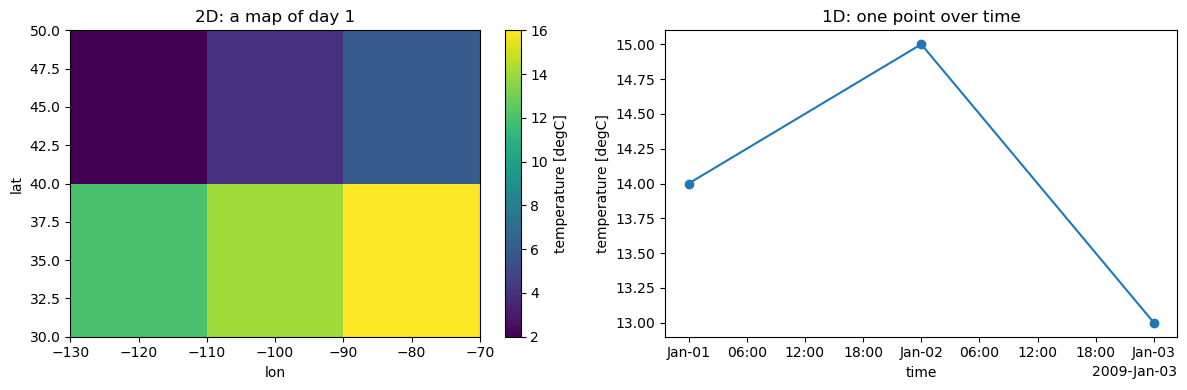

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
toy.isel(time=0).plot(ax=axes[0])
axes[0].set_title("2D: a map of day 1")
toy.sel(lat=35.0, lon=-100.0).plot(ax=axes[1], marker="o")
axes[1].set_title("1D: one point over time")
plt.tight_layout()
plt.show()

## 4. Open the ERA5 temperature data

The temperature is in six files, one per two months. `xr.open_mfdataset` ("multi-file dataset") opens them all as one `Dataset`. `combine="by_coords"` tells it to join them in order of their time coordinate.

The data is **not read into memory yet**. xarray uses a library called *dask* to load only what each calculation needs. That's why opening is fast, and why the summary below says `dask.array`.

In [17]:
temp_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*2m_temperature*.nc")))
print(len(temp_files), "temperature files")

ds_temp = xr.open_mfdataset(temp_files, combine="by_coords")
ds_temp

12 temperature files


<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    t2m         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:39 GRIB to CDM+CF via cfgrib-0.9.1...

Compare this with the toy example. The dimensions are `valid_time`, `latitude` and `longitude`. There is one data variable, `t2m`. `number` is a leftover coordinate from ERA5's ensemble system; it is always 0 here and you can ignore it.

In [18]:
list(ds_temp.data_vars)

['t2m']

In [19]:
T2M = ds_temp["t2m"]    # take the DataArray out of the Dataset
T2M

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<concatenate, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [20]:
print("Units:    ", T2M.attrs.get("units"))
print("Long name:", T2M.attrs.get("long_name"))

Units:     K
Long name: 2 metre temperature


ERA5 stores temperature in kelvin. Convert to Celsius, and set the units again, since arithmetic drops them:

In [21]:
T2M_C = T2M - 273.15
T2M_C.attrs["units"] = "degC"

How big is the dataset, and what does it cover?

In [22]:
print("Start date:", str(T2M_C.valid_time.values[0])[:10])
print("End date:  ", str(T2M_C.valid_time.values[-1])[:10])
print("Days:      ", T2M_C.sizes["valid_time"])
print()
print("Latitude points: ", T2M_C.sizes["latitude"],
      f"({float(T2M_C.latitude.min())} to {float(T2M_C.latitude.max())})")
print("Longitude points:", T2M_C.sizes["longitude"],
      f"({float(T2M_C.longitude.min())} to {float(T2M_C.longitude.max())})")

Start date: 2009-01-01
End date:   2010-12-31
Days:       730

Latitude points:  105 (24.0 to 50.0)
Longitude points: 237 (-125.0 to -66.0)


**Watch out:** the latitudes run from north to south (50 down to 24). A latitude slice must follow the same order: `slice(50, 24)` works, `slice(24, 50)` returns nothing.

In [23]:
T2M_C.coords

Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31

## 5. Maps

`.isel(valid_time=0)` picks the first day. What's left is 2D, so `.plot()` draws a map.

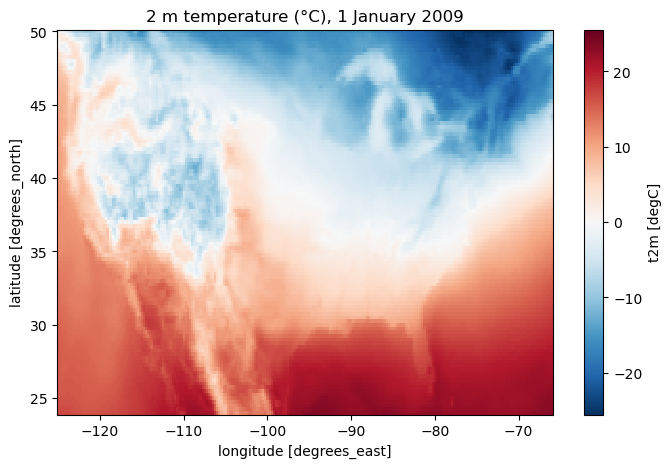

In [24]:
day0 = T2M_C.isel(valid_time=0)

day0.plot()
plt.title("2 m temperature (°C), 1 January 2009")
plt.show()

To compare two maps, give them the **same color scale** with `vmin` and `vmax`. Otherwise each map stretches its colors to its own range and they can't be compared.

`.sel(valid_time="2009-01-15")` selects by date. `method="nearest"` makes it pick the closest day if that exact date is missing.

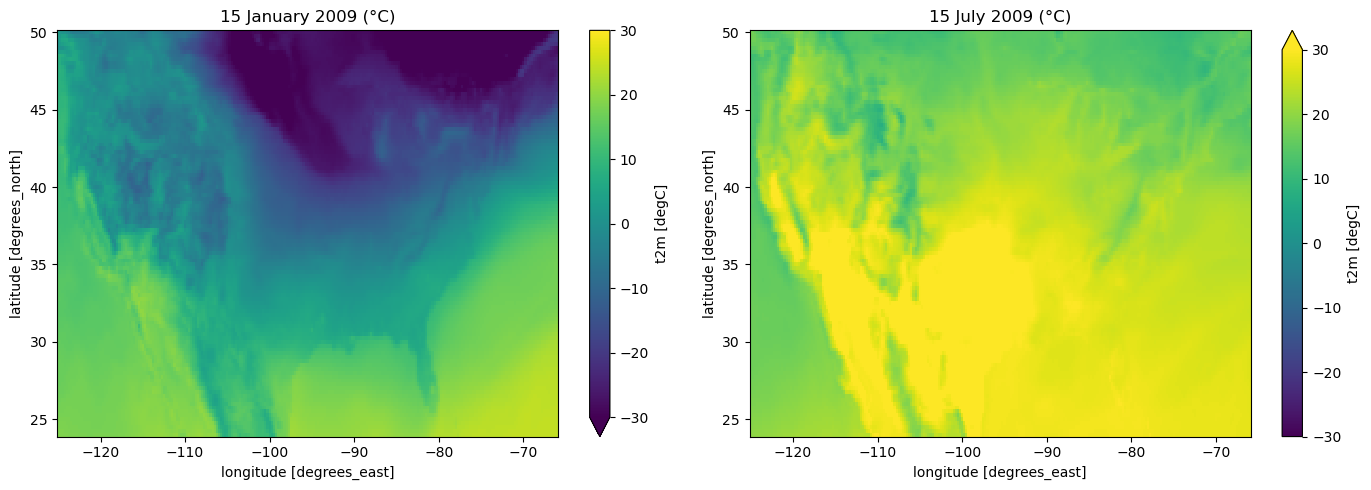

In [25]:
winter = T2M_C.sel(valid_time="2009-01-15", method="nearest")
summer = T2M_C.sel(valid_time="2009-07-15", method="nearest")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

winter.plot(ax=axes[0], vmin=-30, vmax=30)
axes[0].set_title("15 January 2009 (°C)")

summer.plot(ax=axes[1], vmin=-30, vmax=30)
axes[1].set_title("15 July 2009 (°C)")

plt.tight_layout()
plt.show()

## 6. A time series for one city

Selecting one latitude and one longitude leaves a 1D array over time. Chicago is at 41.9° N, 87.6° W. The grid has points every 0.25°, so `method="nearest"` picks the closest one.

Nearest grid point: 42.0 -87.5


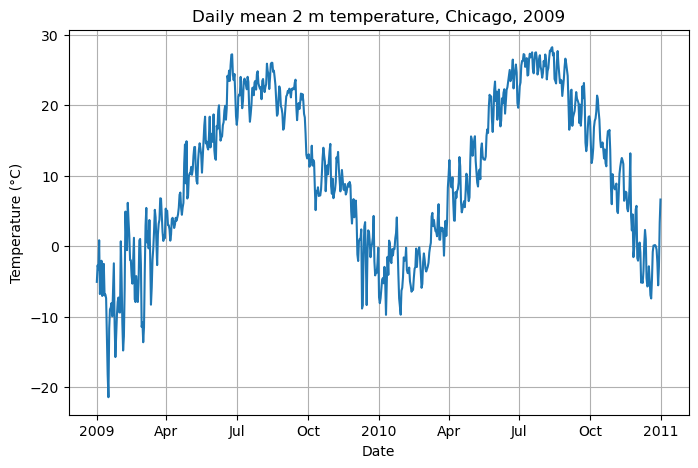

In [26]:
lat_chi = 41.9
lon_chi = -87.6

T_chi = T2M_C.sel(latitude=lat_chi, longitude=lon_chi, method="nearest")
print("Nearest grid point:", float(T_chi.latitude), float(T_chi.longitude))

T_chi.plot()
plt.title("Daily mean 2 m temperature, Chicago, 2009")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

In [27]:
print(f"Mean:               {float(T_chi.mean()):6.1f} °C")
print(f"Standard deviation: {float(T_chi.std()):6.1f} °C")
print(f"Min:                {float(T_chi.min()):6.1f} °C")
print(f"Max:                {float(T_chi.max()):6.1f} °C")

Mean:                 10.1 °C
Standard deviation:   10.9 °C
Min:                 -21.4 °C
Max:                  28.3 °C


`T_chi.mean()` returns a 0-dimensional `DataArray`. `float()` turns it into a plain number. This is also the moment dask actually reads the data from disk.

## 7. Precipitation

Same steps for total precipitation, variable `tp`. ERA5 stores precipitation as a depth of water in **metres**, so multiply by 1000 for millimetres.

In [28]:
precip_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "total_precipitation*.nc")))

ds_precip = xr.open_mfdataset(precip_files, combine="by_coords")
P = ds_precip["tp"]
print("Units in the file:", P.attrs.get("units"))

P_mm = P * 1000
P_mm.attrs["units"] = "mm/day"

Units in the file: m


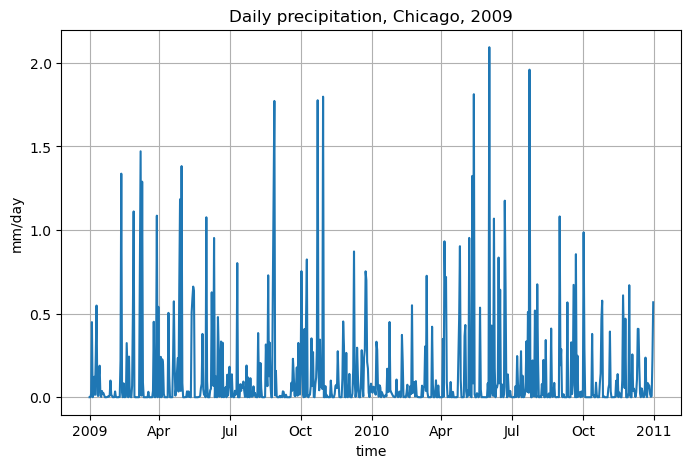

In [29]:
P_chi = P_mm.sel(latitude=lat_chi, longitude=lon_chi, method="nearest")

P_chi.plot()
plt.title("Daily precipitation, Chicago, 2009")
plt.ylabel("mm/day")
plt.grid(True)
plt.show()

### Check the units

Units are easy to get wrong, so check them against something you know. Chicago gets roughly 900 to 1,000 mm of precipitation in a year. Add up the daily values:

In [32]:
print(f"Total for 2009: {float(P_chi.sum() *10):.0f} mm") 

Total for 2009: 967 mm


If the total is close to 900–1,000 mm, the values really are mm per day. If it's about 24 times smaller, each value is the *average hourly* amount for that day (the daily-mean files average ERA5's hourly values), and the daily total is 24 times larger.

**Question:** which is it? Fix `P_mm` above if needed, and rerun this section.

## 8. All the variables together

`open_mfdataset` can open every file at once. With `combine="by_coords"`, it joins the files along time *and* merges the five variables into one `Dataset` on the same grid. (`compat="no_conflicts"` only silences a warning from recent versions of xarray about a future change in how files are merged.)

In [ ]:
ds = xr.open_mfdataset(all_files, combine="by_coords", compat="no_conflicts")
for name, var in ds.data_vars.items():
    print(f"{name:5s} {var.attrs.get('long_name', '')} ({var.attrs.get('units', '')})")

### Wind speed

ERA5 gives the wind as two components: `u10` (west to east) and `v10` (south to north), in m/s. The speed is $\sqrt{u^2 + v^2}$. NumPy functions work directly on `DataArray`s and keep the coordinates:

In [ ]:
wind_speed = np.hypot(ds["u10"], ds["v10"])    # same as sqrt(u**2 + v**2)
wind_speed.attrs["units"] = "m/s"

wind_speed.mean(dim="valid_time").plot(cmap="viridis")
plt.title("Average 10 m wind speed, 2009 (m/s)")
plt.show()

### Pressure and wind on one day

Sea-level pressure (`msl`, in pascals; 100 Pa = 1 hPa) as a map, with wind arrows on top. Plotting an arrow at every grid point would be unreadable, so `.isel(..., slice(None, None, 8))` keeps every 8th point.

In [ ]:
day = "2009-01-15"
msl_hPa = ds["msl"].sel(valid_time=day) / 100
wind = ds[["u10", "v10"]].sel(valid_time=day).isel(
    latitude=slice(None, None, 8), longitude=slice(None, None, 8))

msl_hPa.plot(cmap="viridis", cbar_kwargs={"label": "hPa"})
plt.quiver(wind["longitude"], wind["latitude"], wind["u10"], wind["v10"])
plt.title(f"Sea-level pressure and 10 m wind, {day}")
plt.show()

### Monthly averages

`.resample(valid_time="1MS")` groups the days into calendar months ("MS" = month start), like pandas. Follow it with a reduction such as `.mean()`.

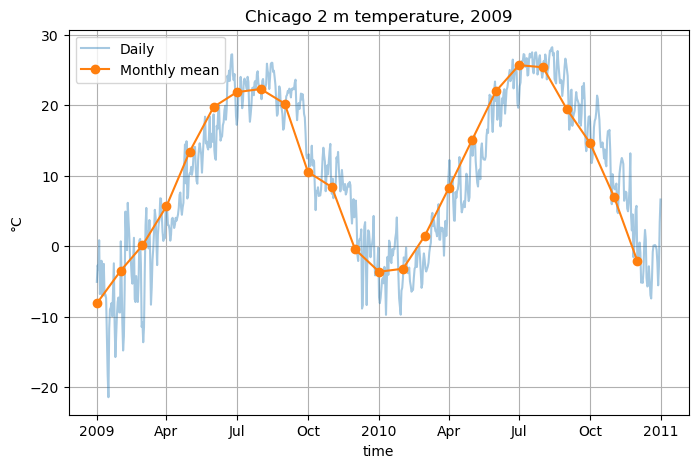

In [33]:
T_chi_monthly = T_chi.resample(valid_time="1MS").mean()

T_chi.plot(alpha=0.4, label="Daily")
T_chi_monthly.plot(marker="o", label="Monthly mean")
plt.title("Chicago 2 m temperature, 2009")
plt.ylabel("°C")
plt.legend()
plt.grid(True)
plt.show()

`.groupby("valid_time.month")` groups by month number instead. Here it gives an average map for each month, and we subtract January from July:

In [ ]:
T_by_month = T2M_C.groupby("valid_time.month").mean()
(T_by_month.sel(month=7) - T_by_month.sel(month=1)).plot(cmap="viridis")
plt.title("July minus January average temperature (°C)")
plt.show()

**Question:** where is the seasonal swing smallest? Why?

### Averages over a region

To average over an area, select it with slices and take the mean over latitude and longitude. One subtlety: grid cells get smaller toward the poles, so each cell should count in proportion to $\cos(\text{latitude})$. xarray's `.weighted()` does this.

Here, a box around the Great Plains. Remember that latitude runs north to south, so the slice does too:

In [ ]:
box = T2M_C.sel(latitude=slice(45, 35), longitude=slice(-105, -95))
weights = np.cos(np.deg2rad(box["latitude"]))

plains = box.weighted(weights).mean(dim=["latitude", "longitude"])

plains.plot()
plt.title("Great Plains average temperature, 2009")
plt.ylabel("°C")
plt.grid(True)
plt.show()

## 9. From xarray to pandas

Most machine-learning tools want a table: one row per example, one column per feature. `.to_dataframe()` turns a `DataArray` or `Dataset` into a pandas `DataFrame`, with one row per combination of coordinates.

Here, one row per day for Chicago, with all five variables as columns:

In [ ]:
chi = ds.sel(latitude=lat_chi, longitude=lon_chi, method="nearest")
df_chi = chi.to_dataframe().drop(columns=["latitude", "longitude", "number"])

df_chi["t2m"] = df_chi["t2m"] - 273.15     # kelvin to Celsius
df_chi["wind_speed"] = np.hypot(df_chi["u10"], df_chi["v10"])
df_chi.head()

In [ ]:
df_chi.describe().round(2)

From here it's the same pandas you used with the Mauna Loa data in Week 2, and the same scikit-learn and PyTorch from Weeks 3 and 4.

Be careful with the size: the full grid is 365 × 105 × 237 ≈ 9 million rows per variable. Select a region or a set of points first.

## 10. Summary

| Task | Code |
|---|---|
| Open many files as one dataset | `xr.open_mfdataset(files, combine="by_coords")` |
| List the variables | `list(ds.data_vars)` |
| Take one variable | `ds["t2m"]` |
| Units and description | `da.attrs["units"]`, `da.attrs["long_name"]` |
| Size of each dimension | `da.sizes` |
| Select by position | `da.isel(valid_time=0)` |
| Select by label | `da.sel(valid_time="2009-07-15")` |
| Closest grid point | `da.sel(latitude=41.9, longitude=-87.6, method="nearest")` |
| A range | `da.sel(latitude=slice(45, 35))` (north to south) |
| Average over a dimension | `da.mean(dim="valid_time")` |
| Monthly means | `da.resample(valid_time="1MS").mean()` |
| Group by month | `da.groupby("valid_time.month").mean()` |
| Area-weighted mean | `da.weighted(np.cos(np.deg2rad(da.latitude))).mean(dim=["latitude", "longitude"])` |
| Plot | `da.plot()` |
| To pandas | `da.to_dataframe()` |

## 11. Things to try

1. **Another city.** Make the temperature and precipitation time series for Los Angeles (34.05° N, 118.25° W). How does its seasonal cycle compare with Chicago's?
2. **Hottest day.** On which day was the US-average temperature highest? Hint: average over latitude and longitude, then use `.idxmax()`.
3. **Wind and pressure.** Pick a stormy day (large precipitation over a big area) and plot pressure with wind arrows. Do the winds circle the low-pressure center?
4. **Toward a project.** Could you predict tomorrow's temperature in Chicago from today's five variables? Build the table with `.to_dataframe()`, add a column with tomorrow's temperature using `.shift(-1)`, and try a linear regression.

THIS IS THE START OF MY PROJECT